# Rooftop solar potential for any city block

Give a longitude/latitude box; the notebook finds a 3DEP lidar project covering it, extracts the buildings and their roof planes from the point cloud, shades each roof with the surrounding buildings and trees, adds up a typical year of sun, writes a 3D model of the block (`.glb` and `.obj`) and plots the energy arriving on every rooftop.

**What the numbers are.** Energy *arriving* on each roof surface in a typical meteorological year (NREL NSRDB, hourly direct and diffuse sunlight at the nearest 4 km site), after shading. It is not electricity: the optional PV estimate multiplies by a module efficiency and performance ratio that are assumptions. Ground and wall reflections, the bright sky around the sun, soiling and snow are not included. Roofs hidden under tree crowns, small outbuildings and dormers are partly or wholly missing from the lidar-derived roofs. Roof planes come from a numpy RANSAC (Open3D was not available in this environment).

The box is limited to about 600 m on a side (runtime and memory); shading from a further 300 m around it is included.

In [1]:
# Parameters: edit these. The default is a 300 m block of West University Place, Houston.
WEST, SOUTH, EAST, NORTH = -95.4352, 29.7162, -95.4318, 29.7188
PROJECT = None          # a 3DEP project name such as 'TX_Coastal_B1_2018'; None picks the newest one covering the box
OUTDIR = 'notebook_output/block'

In [2]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings('ignore')
ROOT = Path.cwd().resolve()
if not (ROOT / 'src').exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'src'))
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from lidar3d import block, rooftop

## 1. Lidar, buildings, roof planes, shading and sunlight

In [3]:
R, T, files = block.run_block(WEST, SOUTH, EAST, NORTH, ROOT / OUTDIR, project=PROJECT, log=lambda s: None)
site, C = R['site'], R['C']
print(f"Lidar project {site['project']}, flown {C.date}; analysis square {2 * site['half']:.0f} m on a side (plus {site['context']:.0f} m of shading context)")
print(f"{len(T)} buildings, {T.roof_area_m2.sum() / 1e4:.2f} ha of roof, {T.total_kwh_yr.sum() / 1e6:.2f} GWh/year arriving on the roofs")
df = R['weather']['df']
print(f"Typical-year sunlight at the NSRDB site {R['weather']['site_lat']:.2f} N, {abs(R['weather']['site_lon']):.2f} {'W' if R['weather']['site_lon'] < 0 else 'E'}: GHI {df.ghi.sum() / 1000:.0f}, DNI {df.dni.sum() / 1000:.0f}, DHI {df.dhi.sum() / 1000:.0f} kWh/m2/yr")

Lidar project TX_Coastal_B1_2018, flown 2018-03-02; analysis square 336 m on a side (plus 300 m of shading context)
76 buildings, 2.52 ha of roof, 29.50 GWh/year arriving on the roofs
Typical-year sunlight at the NSRDB site 29.73 N, 95.42 W: GHI 1745, DNI 1748, DHI 672 kWh/m2/yr


## 2. Energy on every rooftop

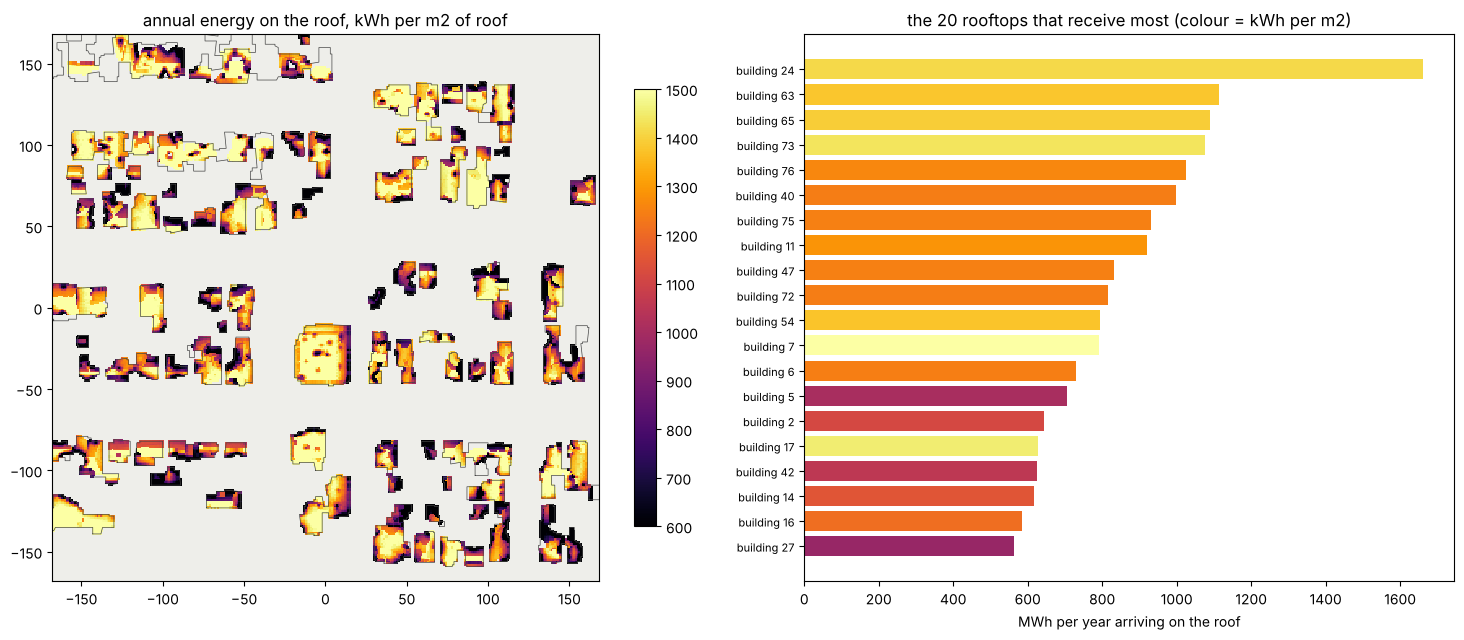

In [4]:
cells = R['cells']
fig, ax = plt.subplots(1, 2, figsize=(15, 6.5), gridspec_kw=dict(width_ratios=[1.1, 1]))
h = site['half']
ax[0].set_facecolor('#eeeeea')
sc = ax[0].scatter(cells.x, cells.y, c=cells.total, s=6, cmap='inferno', norm=Normalize(600, 1500), marker='s', lw=0)
for b in R['B']:
    ax[0].plot(*b.footprint.exterior.xy, color='#444444', lw=0.5)
ax[0].set_xlim(-h, h); ax[0].set_ylim(-h, h); ax[0].set_aspect('equal'); ax[0].set_title('annual energy on the roof, kWh per m2 of roof'); plt.colorbar(sc, ax=ax[0], shrink=0.8)
top = T.sort_values('total_kwh_yr', ascending=False).head(20)
ax[1].barh(range(len(top)), top.total_kwh_yr / 1000, color=plt.cm.inferno(Normalize(600, 1500)(top.mean_total_kwh_m2)))
ax[1].set_yticks(range(len(top))); ax[1].set_yticklabels([f'building {int(b)}' for b in top.building], fontsize=8); ax[1].invert_yaxis(); ax[1].set_xlabel('MWh per year arriving on the roof')
ax[1].set_title('the 20 rooftops that receive most (colour = kWh per m2)')
plt.tight_layout(); plt.show()

In [5]:
cols = ['building', 'footprint_m2', 'height_m', 'planes', 'main_slope_deg', 'main_aspect_deg', 'roof_area_m2', 'mean_total_kwh_m2', 'total_kwh_yr', 'shading_loss_beam', 'suitable_area_m2', 'pv_kwh_yr_est']
T[cols].round(1).sort_values('total_kwh_yr', ascending=False).head(15)

,building,footprint_m2,height_m,planes,main_slope_deg,main_aspect_deg,roof_area_m2,mean_total_kwh_m2,total_kwh_yr,shading_loss_beam,suitable_area_m2,pv_kwh_yr_est
23,24,1176.5,4.3,3,0.9,89.9,1176.1,1413.7,1662694.3,0.2,1083.1,254303.3
61,63,790.5,10.5,8,19.6,273.9,807.6,1380.4,1114759.7,0.1,733.0,169475.0
63,65,1108.0,11.4,7,35.4,180.5,782.3,1394.2,1090634.3,0.2,677.3,163965.1
71,73,722.5,10.4,8,44.3,268.9,748.3,1436.6,1074999.8,0.1,686.6,164738.2
74,76,1732.5,10.9,7,26.2,180.2,811.9,1262.2,1024823.4,0.2,642.3,145652.3
39,40,863.0,10.5,8,29.9,270.4,804.5,1241.6,998840.6,0.2,614.4,138148.1
73,75,1496.5,10.0,8,5.9,15.7,745.8,1249.5,931810.9,0.3,572.9,128930.5
10,11,742.0,10.6,8,33.5,90.3,714.6,1287.5,920038.6,0.2,603.7,136455.3
46,47,662.0,10.5,8,22.9,83.9,666.8,1248.2,832354.5,0.2,531.2,118739.3
70,72,624.5,10.9,8,31.6,270.2,657.0,1240.5,815007.8,0.2,507.8,113829.6


## 3. The block in 3D

The files are written to the output folder: `block.glb` (open in any glTF viewer or Blender) and `block.obj` (with vertex colours). Below is a software-rendered preview.

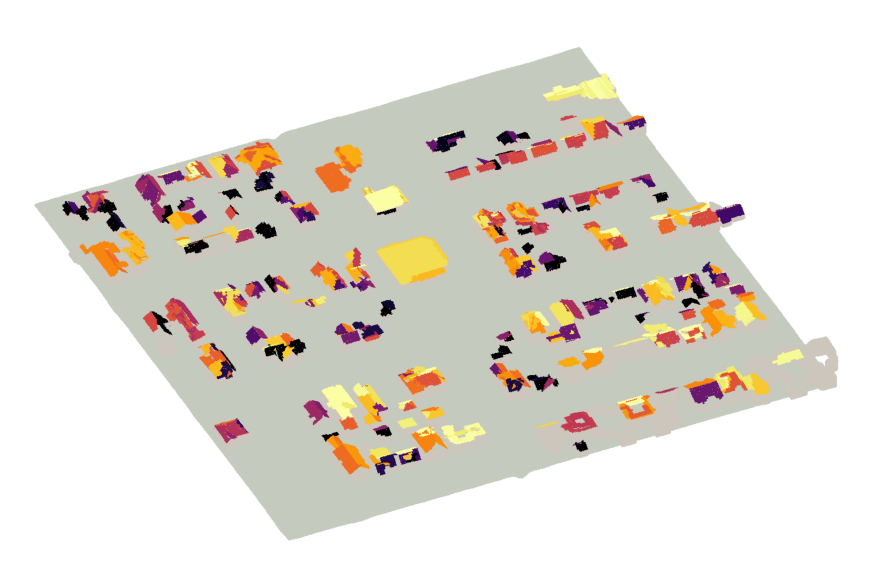

{'glb': '/home/user/lidar-and-3d-modeling/notebook_output/block/block.glb', 'obj': '/home/user/lidar-and-3d-modeling/notebook_output/block/block.obj', 'csv': '/home/user/lidar-and-3d-modeling/notebook_output/block/buildings.csv'}


In [6]:
import trimesh
from lidar3d import render3d
sc = trimesh.load(files['glb'])
pts, cols_ = [], []
for g in sc.geometry.values():
    P, fi = trimesh.sample.sample_surface(g, int(max(g.area * 40, 100)))
    pts.append(P); cols_.append(np.asarray(g.visual.vertex_colors)[g.faces[fi, 0]][:, :3])
im, _ = render3d.render(np.vstack(pts), np.vstack(cols_).astype(np.uint8), az=205, el=38, width=1500, height=1000, splat=2)
plt.figure(figsize=(11, 7.5)); plt.imshow(im); plt.axis('off'); plt.show()
print({k: str(v) for k, v in files.items()})

## 4. Optional: electricity estimate (assumptions, not measurements)

In [7]:
EFFICIENCY, PERFORMANCE_RATIO, MIN_KWH_M2 = 0.20, 0.80, 1000.0   # module efficiency, system losses, screening level for a usable roof cell
ok = cells.total >= MIN_KWH_M2
kwh = float((cells.total * cells.area)[ok].sum() * EFFICIENCY * PERFORMANCE_RATIO)
print(f"{(cells.area[ok].sum() / cells.area.sum()) * 100:.0f}% of the roof area receives at least {MIN_KWH_M2:.0f} kWh/m2/yr; panels there would make about {kwh / 1e6:.2f} GWh of electricity a year under these assumptions")

71% of the roof area receives at least 1000 kWh/m2/yr; panels there would make about 4.00 GWh of electricity a year under these assumptions
